[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/antfolk/BMEN35_2026/blob/main/Session1/BMEN35_Ex1_01_Data_and_baselines.ipynb)

# First, look at the data

Before we fit a model, let's find out what the data look like. In this notebook we will load the data, check the labels, make a couple of plots, and then try a very simple baseline.

We will use the **Wisconsin Diagnostic Breast Cancer** dataset that comes with scikit-learn. It has 569 observations and 30 numeric features. The measurements describe cell nuclei from digitized images of fine needle aspirates. Each observation is labelled malignant or benign.

The model only sees these numbers. It does not see the original images or the full clinical context. This is a small teaching example, so we use it to learn the workflow, not to make medical claims.

Let's run one cell at a time and stop to look at the outputs as we go.


## 1. Import the libraries

We will use pandas to look at the table, Matplotlib to make plots, and scikit-learn to load the data and fit a baseline. The dataset is included with scikit-learn, so there is nothing to download.


In [2]:
# Tables and plots help us inspect the data before modeling.
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn supplies the dataset, the split helper, and a simple baseline.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

# These tools help us describe the baseline's predictions.
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

## 2. Load the data

The loader gives us the feature table, the class labels, and names for both features and classes. We will call the feature table `X` and the labels `y`. You will see these names in many machine-learning examples.


In [4]:
# Load the dataset as a pandas DataFrame so column names are kept.
data = load_breast_cancer(as_frame=True)

# X contains the measurements; y contains one class label per observation.
X = data.data
y = data.target

print('Dataset name:', data.DESCR.splitlines()[0])
print('Number of observations:', X.shape[0])
print('Number of features:', X.shape[1])
print('Feature names:')
print(list(X.columns))

Dataset name: .. _breast_cancer_dataset:
Number of observations: 569
Number of features: 30
Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


## 3. What do the target numbers mean?

The labels are numbers, but they are just category codes. Here, `0` means malignant and `1` means benign. Let's check this in the dataset rather than guessing.

The next cell makes a small table with the number and its class name. It also shows the first few observations with their labels.


In [5]:
# Display the mapping from numeric target code to human-readable label.
label_mapping = pd.DataFrame({
    'target code': range(len(data.target_names)),
    'class name': data.target_names
})
display(label_mapping)

# Show the first few observations together with their readable labels.
first_rows = X.head().copy()
first_rows['target code'] = y.head()
first_rows['class name'] = [data.target_names[value] for value in y.head()]
display(first_rows)

,target code,class name
0,0,malignant
1,1,benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target code,class name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


## 4. Have a look at the feature values

The first few rows only show a small part of the table. The summary below gives us a better idea of the ranges and typical values. It is a useful first check, but it cannot tell us whether the measurements or labels are correct.

As you look at the output, check for missing values and ask whether the features are on similar scales. Do any values look surprising?


In [6]:
# Summarize each numeric feature. Rounding makes the table easier to scan.
display(X.describe().round(2).T)

# Count missing values in each feature column.
missing_per_feature = X.isna().sum()
print('Total missing feature values:', missing_per_feature.sum())
print('Features with missing values:', list(missing_per_feature[missing_per_feature > 0].index))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


Total missing feature values: 0
Features with missing values: []


## 5. Check how many observations are in each class

Class balance just means how many rows belong to each class. This matters because a model can get a decent accuracy by mostly predicting the larger class.

Let's count the classes and draw a bar plot. Before moving on, think about what would happen if we always guessed the most common class.


,number of observations
malignant,212
benign,357


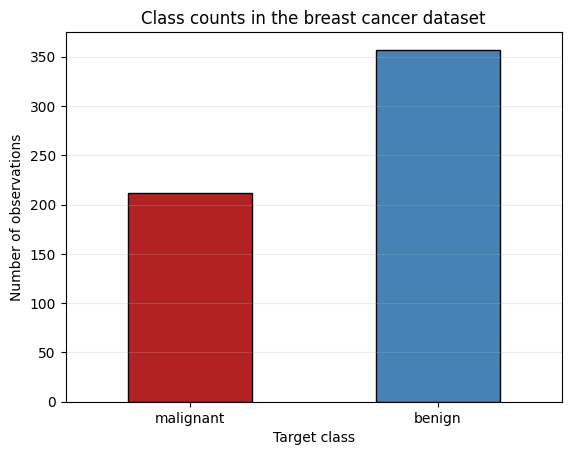

In [7]:
# Count how many observations belong to each target code.
class_counts = y.value_counts().sort_index()

# Replace numeric codes with readable labels for the display.
class_counts.index = [data.target_names[code] for code in class_counts.index]
display(class_counts.rename('number of observations').to_frame())

# Plot the number of observations in each class.
class_counts.plot(kind='bar', color=['firebrick', 'steelblue'], edgecolor='black')
plt.title('Class counts in the breast cancer dataset')
plt.xlabel('Target class')
plt.ylabel('Number of observations')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)
plt.show()

### Stop and look at the plot

1. Which class has more observations?
2. If we always guessed the larger class, how many would we get right?
3. Would that be enough for a screening task? Why or why not?

Keep those answers in mind. We will fit that simple majority-class model in a moment.


## 6. Plot two features

We have 30 features, so we cannot show the whole dataset in one ordinary scatter plot. Let's pick two: mean radius and mean texture. Each dot is one observation, and its color shows the class.

This is only one view of the data. The model will use all 30 features, and this plot cannot show everything those features tell us.


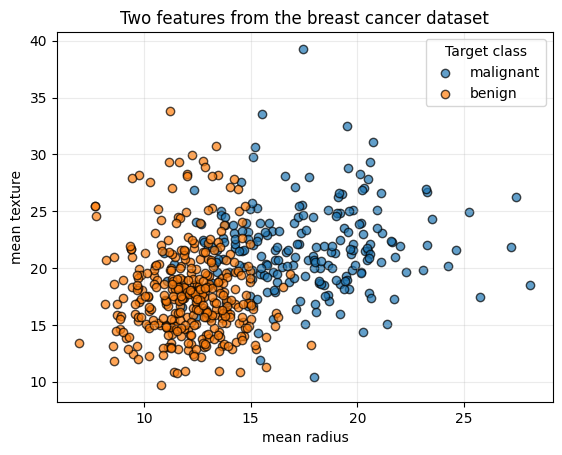

In [8]:
# Choose two named features so we know what is on each axis.
feature_x = 'mean radius'
feature_y = 'mean texture'

# Plot malignant and benign observations separately so the legend is clear.
for target_code, class_name in enumerate(data.target_names):
    rows_in_class = y == target_code
    plt.scatter(
        X.loc[rows_in_class, feature_x],
        X.loc[rows_in_class, feature_y],
        label=class_name,
        alpha=0.7,
        edgecolor='black'
    )

plt.xlabel(feature_x)
plt.ylabel(feature_y)
plt.title('Two features from the breast cancer dataset')
plt.legend(title='Target class')
plt.grid(alpha=0.25)
plt.show()

### Stop and look at the scatter plot

1. Do the two classes separate perfectly in this plot?
2. What do you notice about the groups of points?
3. Can we decide from this plot alone whether the two features are enough?

This is why we plot the data before fitting a model. A plot can show a pattern, but it also shows what we still do not know.


## 7. Split the data into training and test sets

Now let's hold some observations aside. The model will learn from the training set, and we will use the test set at the end to see how it does on observations it has not seen before.

`stratify=y` keeps roughly the same class balance in both sets. `random_state=42` makes the split repeatable, so you should see the same result each time you run this notebook.


In [9]:
# Keep 25% of observations for the held-out test set.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print('Training observations:', len(X_train))
print('Test observations:', len(X_test))
print('Training class proportions:')
print(y_train.value_counts(normalize=True).sort_index().rename(index=dict(enumerate(data.target_names))))
print('Test class proportions:')
print(y_test.value_counts(normalize=True).sort_index().rename(index=dict(enumerate(data.target_names))))

Training observations: 426
Test observations: 143
Training class proportions:
target
malignant    0.373239
benign       0.626761
Name: proportion, dtype: float64
Test class proportions:
target
malignant    0.370629
benign       0.629371
Name: proportion, dtype: float64


## 8. Make a simple baseline

A baseline gives us something simple to compare with. This one always predicts the class that appears most often in the training set. It does not look at any of the measurements.

If a more complicated model cannot do better than this, we need to understand why before we get excited about it.


In [10]:
# Create a classifier that always predicts the most common training class.
baseline = DummyClassifier(strategy='most_frequent')

# Fit the baseline using the training data only.
baseline.fit(X_train, y_train)

# Predict labels for the held-out test observations.
baseline_predictions = baseline.predict(X_test)

print('Predicted class codes:', sorted(set(baseline_predictions)))
print('Predicted class name:', data.target_names[baseline_predictions[0]])

Predicted class codes: [np.int64(1)]
Predicted class name: benign


## 9. Look at the baseline's predictions

The confusion matrix counts which classes were predicted correctly and which were missed. The report gives us precision, recall and F1 for each class.

The rows and columns below are shown in the order malignant, benign. Check the labels before you interpret the numbers. In a screening discussion, we especially want to look at malignant recall: how many malignant cases did the model find?


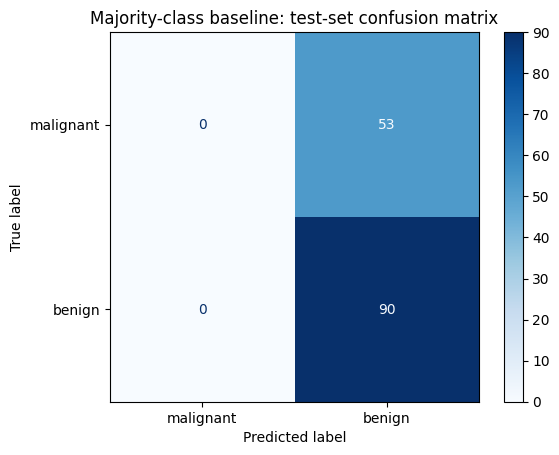

              precision    recall  f1-score   support

   malignant       0.00      0.00      0.00        53
      benign       0.63      1.00      0.77        90

    accuracy                           0.63       143
   macro avg       0.31      0.50      0.39       143
weighted avg       0.40      0.63      0.49       143



In [11]:
# Give class names explicitly so matrix rows and columns are readable.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    display_labels=data.target_names,
    cmap='Blues'
)
plt.title('Majority-class baseline: test-set confusion matrix')
plt.show()

# Print one row of metrics per class, with labels in the same order as code 0 and 1.
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=data.target_names,
    zero_division=0
))

## 10. What does this baseline tell us?

Use the class counts, confusion matrix and report to answer these questions:

1. Which class does the baseline always predict? Where can you see that in the confusion matrix?
2. What is its recall for malignant cases? What does that number mean here?
3. Why is accuracy not enough to describe this baseline?
4. What would you want to know about the data before using them in a new hospital or population?

That is the point of this notebook: get to know the data, understand the labels, and set a simple reference before we start building models. In the next notebook we will use a tiny artificial dataset to look at how a decision tree makes a split.


Answers
1. The baseline always predicts benign. You can se that since the malignant label is zero in the confusion matrix.

2. The recall for malignant cases is zero. That means that the model does not identify any of the true positive cases.

3. Accuracy can be misleading in unbalanced classes. Though, these classes seem to be fairly balanced. But accuracy also does not take in consideration that a false negative is far more serious than a false positive.

4. Maybe how this class balance would relate to a new population.